# Ajuste de curvas y regresión

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. DATOS DE EJEMPLO

In [2]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2.1, 4.0, 6.2, 8.1, 10.3], dtype=float)

# 2. REGRESIÓN LINEAL MANUAL

In [3]:
n = len(x)

b1 = (
    n * np.sum(x * y)
    - np.sum(x) * np.sum(y)
) / (
    n * np.sum(x ** 2)
    - np.sum(x) ** 2
)

b0 = np.mean(y) - b1 * np.mean(x)

print("REGRESIÓN LINEAL")
print("Pendiente b1:", b1)
print("Intercepto b0:", b0)
print(f"Modelo: y = {b0:.4f} + {b1:.4f}x")

REGRESIÓN LINEAL
Pendiente b1: 2.05
Intercepto b0: -0.009999999999999787
Modelo: y = -0.0100 + 2.0500x


# 3. PREDICCIONES Y RESIDUOS

In [5]:
y_pred = b0 + b1 * x
residuos = y - y_pred

print("\nPREDICCIONES Y RESIDUOS")
for xi, yi, yp, e in zip(x, y, y_pred, residuos):
    print(
        f"x={xi:.2f} | observado={yi:.2f} | "
        f"predicho={yp:.2f} | residuo={e:.4f}"
    )



PREDICCIONES Y RESIDUOS
x=1.00 | observado=2.10 | predicho=2.04 | residuo=0.0600
x=2.00 | observado=4.00 | predicho=4.09 | residuo=-0.0900
x=3.00 | observado=6.20 | predicho=6.14 | residuo=0.0600
x=4.00 | observado=8.10 | predicho=8.19 | residuo=-0.0900
x=5.00 | observado=10.30 | predicho=10.24 | residuo=0.0600


# 4. SUMA DE CUADRADOS, MSE Y RMSE

In [6]:
sse = np.sum(residuos ** 2)
mse = np.mean(residuos ** 2)
rmse = np.sqrt(mse)

print("\nMÉTRICAS")
print("SSE:", sse)
print("MSE:", mse)
print("RMSE:", rmse)


MÉTRICAS
SSE: 0.02700000000000008
MSE: 0.005400000000000016
RMSE: 0.07348469228349545


# 5. R^2

In [7]:
ss_total = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - sse / ss_total

print("R^2:", r2)


R^2: 0.999357937791306


# 6. GRÁFICO CON DATOS, RECTA, PREDICCIONES Y RESIDUOS

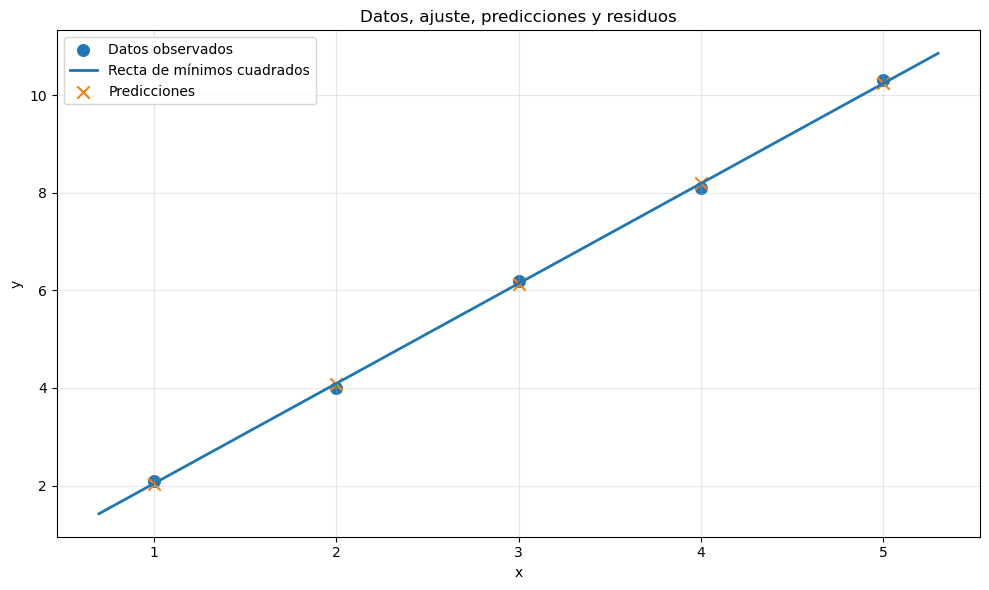

In [8]:
x_linea = np.linspace(np.min(x) - 0.3, np.max(x) + 0.3, 200)
y_linea = b0 + b1 * x_linea

plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    s=70,
    label="Datos observados"
)

plt.plot(
    x_linea,
    y_linea,
    linewidth=2,
    label="Recta de mínimos cuadrados"
)

plt.scatter(
    x,
    y_pred,
    marker="x",
    s=80,
    label="Predicciones"
)

for xi, yi, yp in zip(x, y, y_pred):
    plt.plot(
        [xi, xi],
        [yi, yp],
        linestyle="--",
        linewidth=1
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Datos, ajuste, predicciones y residuos")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 7. GRÁFICO EXCLUSIVO DE RESIDUOS

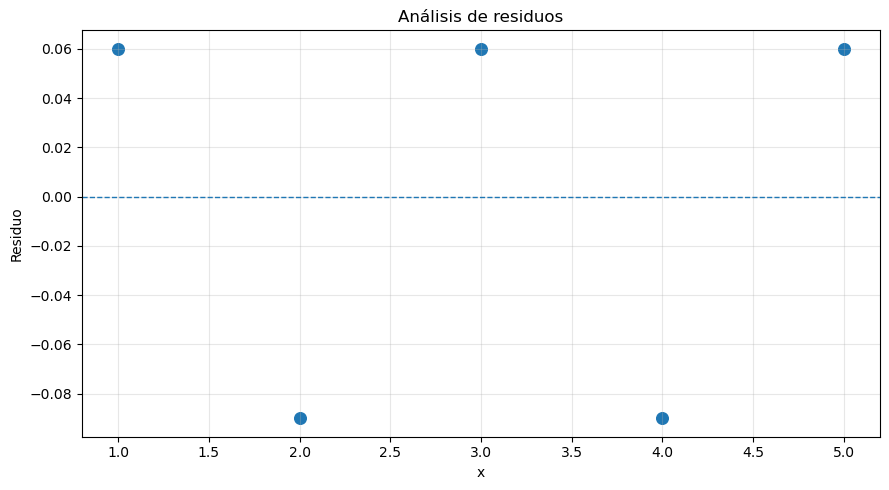

In [9]:
plt.figure(figsize=(9, 5))

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.scatter(x, residuos, s=70)

plt.xlabel("x")
plt.ylabel("Residuo")
plt.title("Análisis de residuos")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. REGRESIÓN LINEAL CON POLYFIT

In [10]:
coef_lineal = np.polyfit(x, y, 1)

modelo_lineal = np.poly1d(coef_lineal)

print("\nPOLYFIT - REGRESIÓN LINEAL")
print("Coeficientes:", coef_lineal)
print("Modelo:", modelo_lineal)



POLYFIT - REGRESIÓN LINEAL
Coeficientes: [ 2.05 -0.01]
Modelo:  
2.05 x - 0.01


# 9. EJEMPLO POLINOMIAL

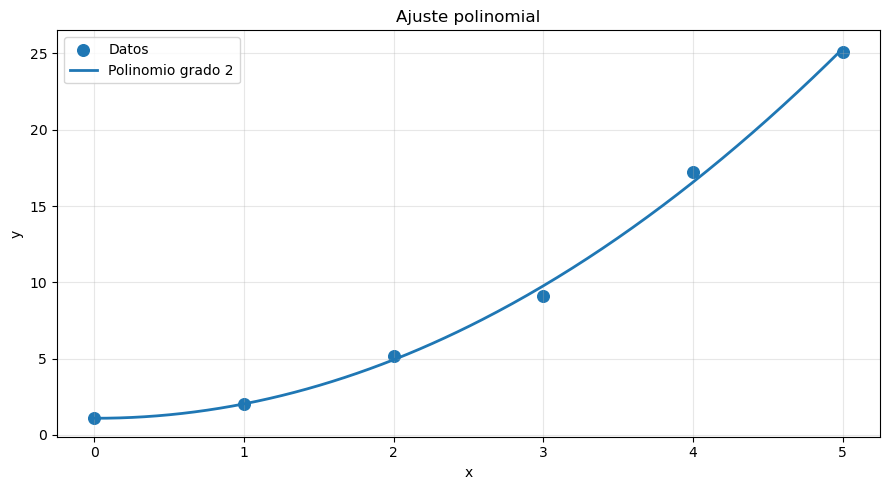


POLINOMIO CUADRÁTICO
Coeficientes: [ 0.975      -0.03214286  1.09285714]
Modelo:        2
0.975 x - 0.03214 x + 1.093


In [11]:
x2 = np.array([0, 1, 2, 3, 4, 5], dtype=float)

y2 = np.array([
    1.1,
    2.0,
    5.2,
    9.1,
    17.2,
    25.1
], dtype=float)

coef_cuadratico = np.polyfit(x2, y2, 2)

modelo_cuadratico = np.poly1d(coef_cuadratico)

x2_modelo = np.linspace(
    np.min(x2),
    np.max(x2),
    300
)

y2_modelo = modelo_cuadratico(x2_modelo)

plt.figure(figsize=(9, 5))

plt.scatter(
    x2,
    y2,
    s=70,
    label="Datos"
)

plt.plot(
    x2_modelo,
    y2_modelo,
    linewidth=2,
    label="Polinomio grado 2"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Ajuste polinomial")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nPOLINOMIO CUADRÁTICO")
print("Coeficientes:", coef_cuadratico)
print("Modelo:", modelo_cuadratico)


# 10. MODELO FÍSICO: MOVIMIENTO UNIFORMEMENTE ACELERADO


MODELO FÍSICO
d0 = 0.026071428571428128
v0 = -0.07267857142856916
a  = 9.919642857142852


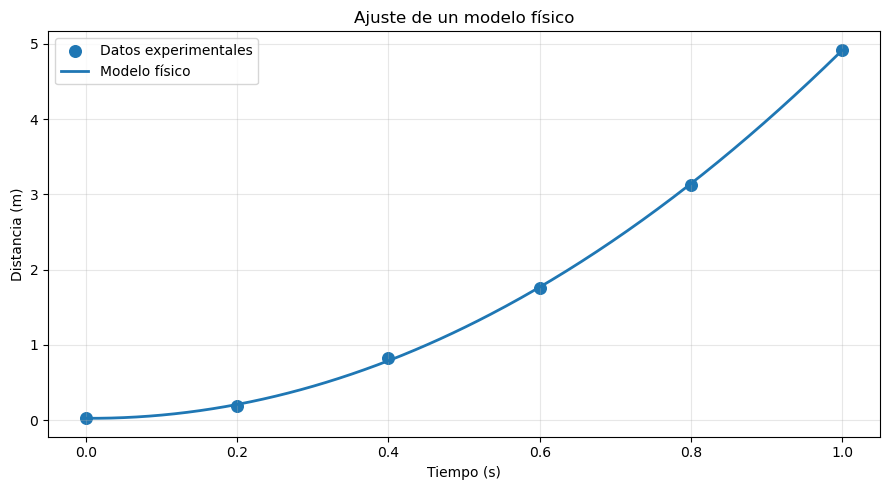

In [12]:
t = np.array([
    0.0,
    0.2,
    0.4,
    0.6,
    0.8,
    1.0
])

d = np.array([
    0.03,
    0.19,
    0.82,
    1.76,
    3.13,
    4.92
])

# Modelo:
#
# d(t) = d0 + v0*t + (1/2)*a*t^2
#
# np.polyfit devuelve:
#
# A*t^2 + B*t + C

coef_fisico = np.polyfit(t, d, 2)

A, B, C = coef_fisico

a = 2 * A
v0 = B
d0 = C

print("\nMODELO FÍSICO")
print("d0 =", d0)
print("v0 =", v0)
print("a  =", a)

t_modelo = np.linspace(
    np.min(t),
    np.max(t),
    300
)

d_modelo = (
    d0
    + v0 * t_modelo
    + 0.5 * a * t_modelo ** 2
)

plt.figure(figsize=(9, 5))

plt.scatter(
    t,
    d,
    s=70,
    label="Datos experimentales"
)

plt.plot(
    t_modelo,
    d_modelo,
    linewidth=2,
    label="Modelo físico"
)

plt.xlabel("Tiempo (s)")
plt.ylabel("Distancia (m)")
plt.title("Ajuste de un modelo físico")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 11. RESIDUOS DEL MODELO FÍSICO


RESIDUOS DEL MODELO FÍSICO
RMSE: 0.016009669697077587


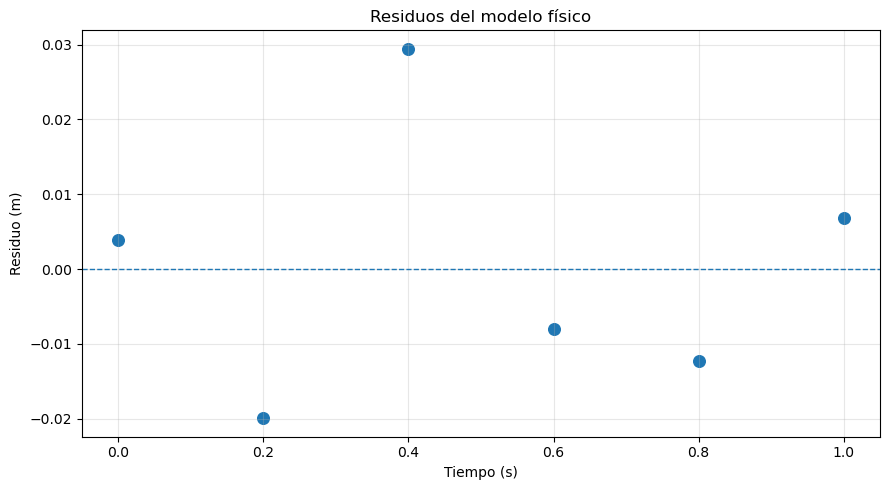

In [14]:
d_pred = (
    d0
    + v0 * t
    + 0.5 * a * t ** 2
)

residuos_fisicos = d - d_pred

rmse_fisico = np.sqrt(
    np.mean(residuos_fisicos ** 2)
)

print("\nRESIDUOS DEL MODELO FÍSICO")
print("RMSE:", rmse_fisico)

plt.figure(figsize=(9, 5))

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.scatter(
    t,
    residuos_fisicos,
    s=70
)

plt.xlabel("Tiempo (s)")
plt.ylabel("Residuo (m)")
plt.title("Residuos del modelo físico")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 12. REGRESIÓN NO LINEAL: MODELO EXPONENCIAL


REGRESIÓN NO LINEAL
A = 1.8597252076037272
k = 0.4199663881929964


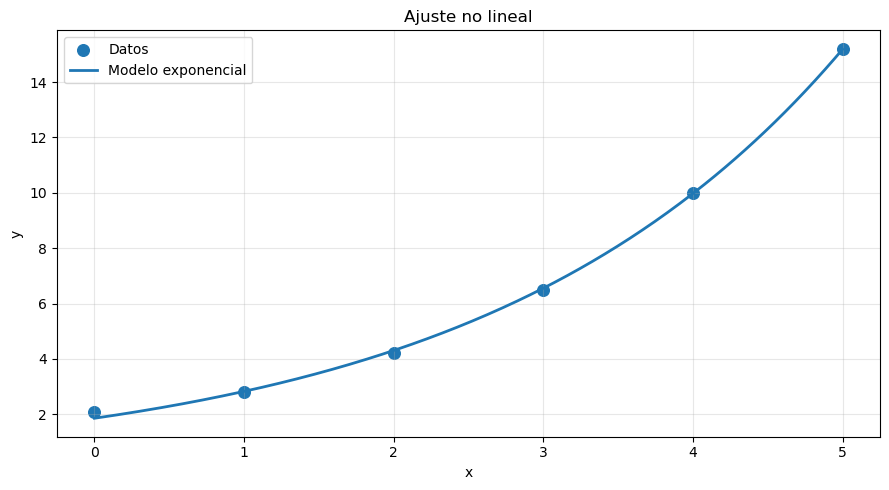

In [15]:
x3 = np.array([
    0, 1, 2, 3, 4, 5
], dtype=float)

y3 = np.array([
    2.1,
    2.8,
    4.2,
    6.5,
    10.0,
    15.2
], dtype=float)


def modelo_exponencial(x, A, k):
    """
    Modelo:
        y = A * exp(k*x)
    """
    return A * np.exp(k * x)


parametros, covarianza = curve_fit(
    modelo_exponencial,
    x3,
    y3,
    p0=[2, 0.4]
)

A_exp, k_exp = parametros

print("\nREGRESIÓN NO LINEAL")
print("A =", A_exp)
print("k =", k_exp)

x3_modelo = np.linspace(
    np.min(x3),
    np.max(x3),
    300
)

y3_modelo = modelo_exponencial(
    x3_modelo,
    A_exp,
    k_exp
)

plt.figure(figsize=(9, 5))

plt.scatter(
    x3,
    y3,
    s=70,
    label="Datos"
)

plt.plot(
    x3_modelo,
    y3_modelo,
    linewidth=2,
    label="Modelo exponencial"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Ajuste no lineal")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 13. COMPARACIÓN DE MODELOS

In [16]:
def calcular_rmse(y_real, y_estimado):
    """Calcula la raíz del error cuadrático medio."""
    return np.sqrt(
        np.mean((y_real - y_estimado) ** 2)
    )


rmse_lineal = calcular_rmse(
    y,
    y_pred
)

print("\nCOMPARACIÓN")
print("RMSE modelo lineal:", rmse_lineal)


COMPARACIÓN
RMSE modelo lineal: 0.07348469228349545


# 14. RETO FINAL PARA ESTUDIANTES

Utilizar el siguiente conjunto de datos.

import numpy as np

t = np.array([
    0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0,
    3.5, 4.0, 4.5, 5.0, 5.5, 6.0
])

x = np.array([
    0.8, 2.1, 4.1, 6.9, 10.1, 13.9, 18.2,
    22.9, 28.1, 33.9, 40.2, 46.8, 54.1
])

El estudiante debe:
1. Graficar los datos.
2. Proponer un modelo.
3. Ajustar los parámetros.
4. Generar predicciones.
5. Calcular residuos.
6. Calcular RMSE.
7. Graficar datos y modelo.
8. Graficar residuos.
9. Interpretar los parámetros.
10. Realizar una predicción.

Pregunta fundamental:
"¿Por qué eligieron ese modelo y no otro?"